# Лабораторная работа №3
## Линейная регрессия методом наименьших квадратов

**Выполнил:** Коршун Артём, группа P3319  
**Вариант:** 8, чётный номер в списке  
**Модуль:** 2. Методы машинного обучения  

## Задание:
1. Выбор датасетов:
    - Студенты с **четным** порядковым номером в группе должны использовать набор данных о жилье в Калифорнии Скачать тут
    - Студенты с **нечетным** порядковым номером в группе должны использовать про обучение студентов
2. Получите и визуализируйте (графически) статистику по датасету (включая количество, среднее значение, стандартное отклонение, минимум, максимум и различные квантили).
3. Проведите предварительную обработку данных, включая обработку отсутствующих значений, кодирование категориальных признаков и нормировка.
4. Разделите данные на обучающий и тестовый наборы данных.
5. Реализуйте линейную регрессию с использованием метода наименьших квадратов без использования сторонних библиотек, кроме NumPy и Pandas (для использования коэффициентов использовать библиотеки тоже нельзя). Использовать минимизацию суммы квадратов разностей между фактическими и предсказанными значениями для нахождения оптимальных коэффициентов.
6. Постройте **три модели** с различными наборами признаков.
7. Для каждой модели проведите оценку производительности, используя метрику коэффициент детерминации, чтобы измерить, насколько хорошо модель соответствует данным.
8. Сравните результаты трех моделей и сделайте выводы о том, какие признаки работают лучше всего для каждой модели.
9. Бонусное задание
    - Ввести синтетический признак при построении модели

## Реализация:

### 1. Выбор датасетов

Так как мой порядковый номер в группе — 8, я использую датасет о жилье в Калифорнии. 

При первом осмотре в датасете есть поля:

- `longitude` — долгота
- `latitude` — широта
- `housing_median_age` — медианный возраст жилья
- `total_rooms` — всего комнат
- `total_bedrooms` — всего спален
- `population` — население
- `households` — домохозяйства
- `median_income` — медианный доход, в единицах десятков тысяч долларов
- `median_house_value` — медианная стоимость жилья в долларах

Одна строка — район переписи. Предсказывать будем медианную стоимость жилья района по его остальным характеристикам. Поэтому `median_house_value` выбрано целью, а остальные восемь полей — входными признаками.

### 2. Получите и визуализируйте (графически) статистику по датасету (включая количество, среднее значение, стандартное отклонение, минимум, максимум и различные квантили).

Считаю количество известных значений, среднее, стандартное отклонение, минимум, максимум и квантили. Это позволяет проверить состав данных и увидеть, насколько различаются диапазоны столбцов. Квантили: 10%, 25%, 50%, 75% и 90%.

In [1]:
import pandas as pd

TARGET = "median_house_value"
raw = pd.read_csv("data/california_housing_train.csv")

print("Размер датасета:", raw.shape)
display(raw.head())

Размер датасета: (17000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [2]:
stats = raw.describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]).T
display(stats.round(3))
print("Максимальная стоимость:", float(raw[TARGET].max()))
print("Строк на верхней границе стоимости:", int((raw[TARGET] == raw[TARGET].max()).sum()))

,count,mean,std,min,10%,25%,50%,75%,90%,max
longitude,17000.0,-119.562,2.005,-124.35,-122.280,-121.790,-118.490,-118.000,-117.240,-114.31
latitude,17000.0,35.625,2.137,32.54,33.620,33.930,34.250,37.720,38.480,41.95
housing_median_age,17000.0,28.589,12.587,1.00,12.000,18.000,29.000,37.000,46.000,52.00
total_rooms,17000.0,2643.664,2179.947,2.00,949.000,1462.000,2127.000,3151.250,4677.100,37937.00
total_bedrooms,17000.0,539.411,421.499,1.00,199.000,297.000,434.000,648.250,968.000,6445.00
population,17000.0,1429.574,1147.853,3.00,514.000,790.000,1167.000,1721.000,2578.200,35682.00
households,17000.0,501.222,384.521,1.00,185.000,282.000,409.000,605.250,893.000,6082.00
median_income,17000.0,3.884,1.908,0.50,1.911,2.566,3.545,4.767,6.195,15.00
median_house_value,17000.0,207300.912,115983.764,14999.00,81900.000,119400.000,180400.000,265000.000,379600.000,500001.00


Максимальная стоимость: 500001.0
Строк на верхней границе стоимости: 814


В файле 17000 строк. Максимальная стоимость — 500001 доллар. На максимальном значении наблюдается скопление: 814 строк имеют стоимость 500001 доллар. Это указывает на возможное ограничение сверху, которое согласуется с описанием исходных данных переписи.

Для графической проверки отдельно показываю количество значений, средние и std с квантилями, затем гистограммы. У столбцов разные единицы: число комнат и координаты нельзя содержательно сравнивать только по размеру чисел.

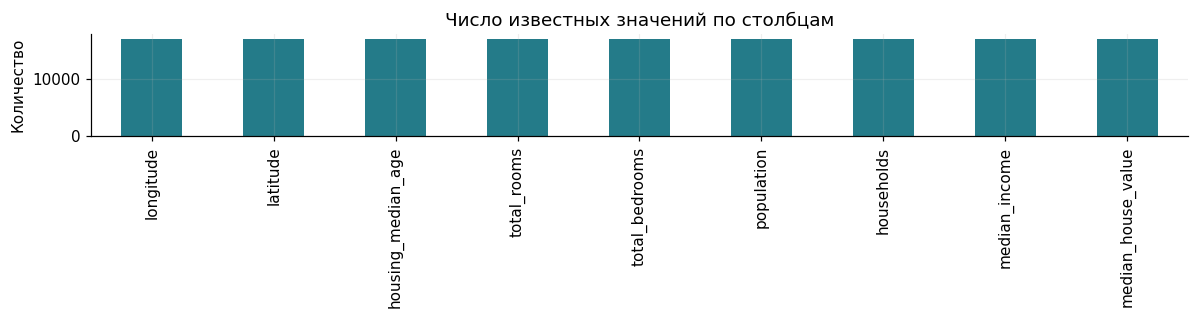

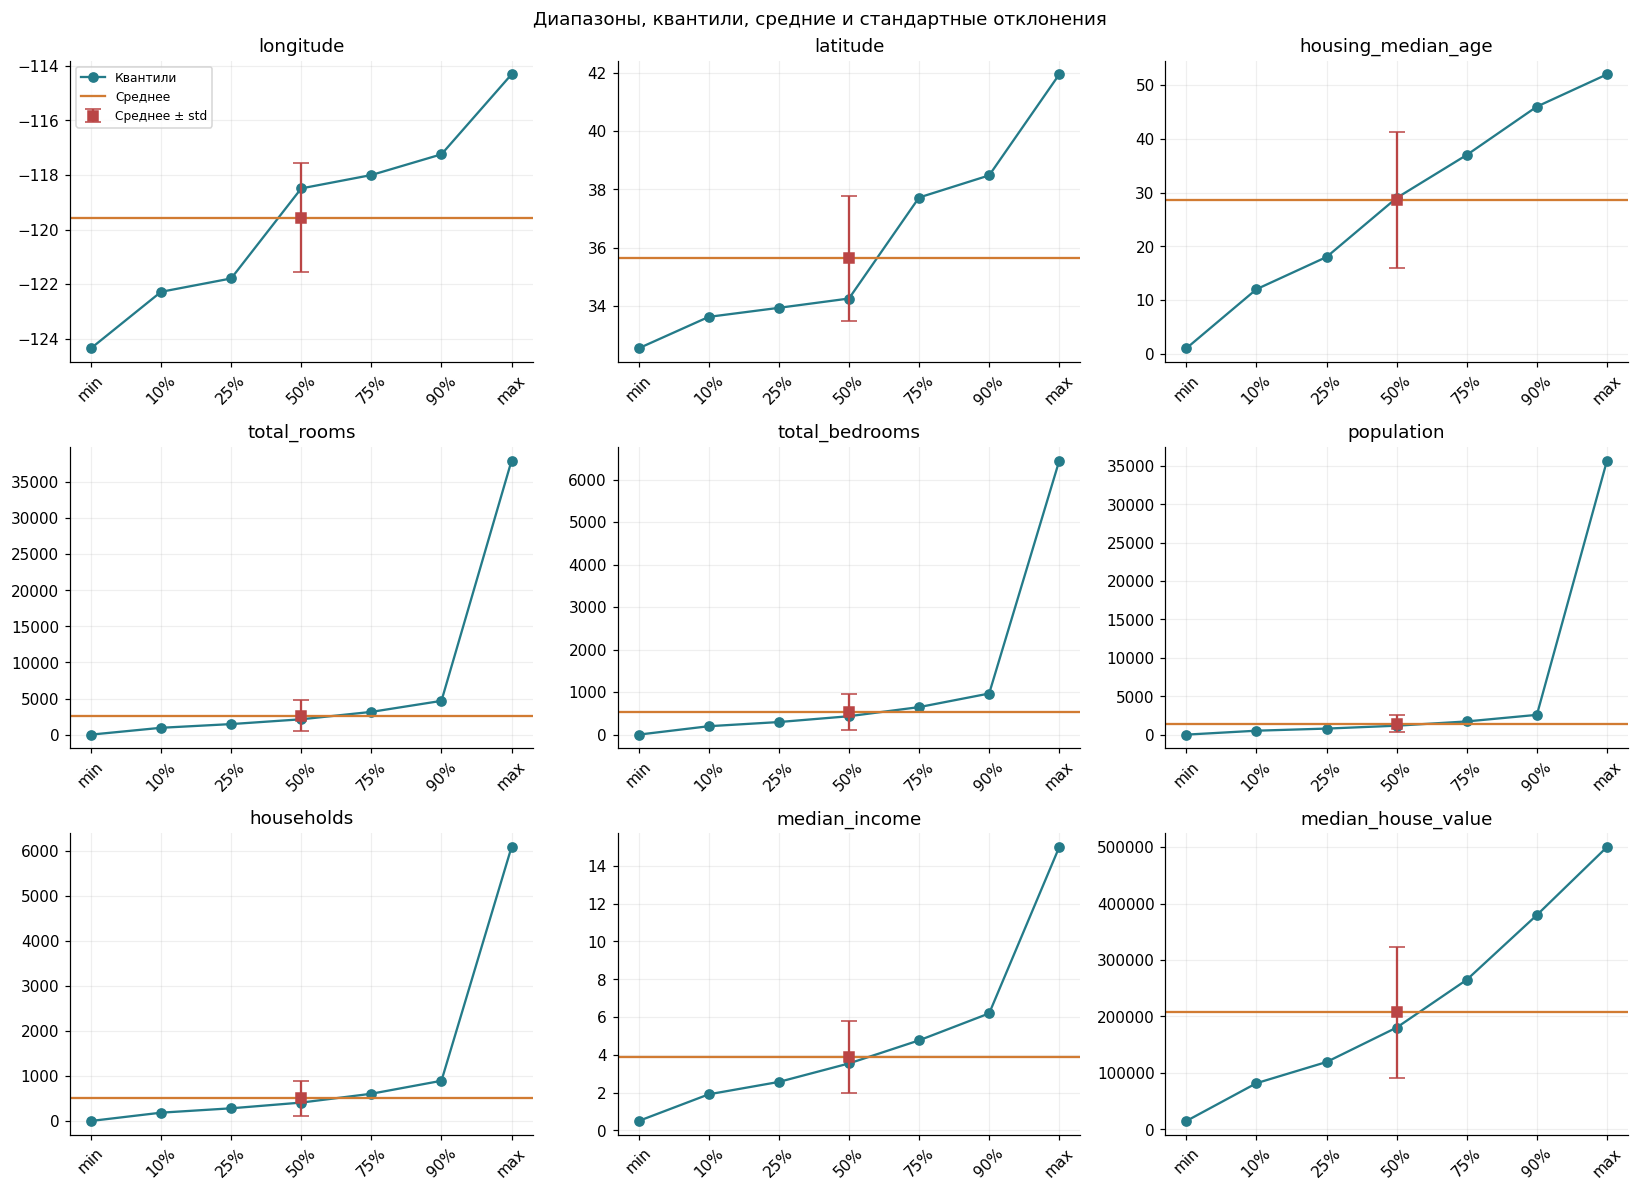

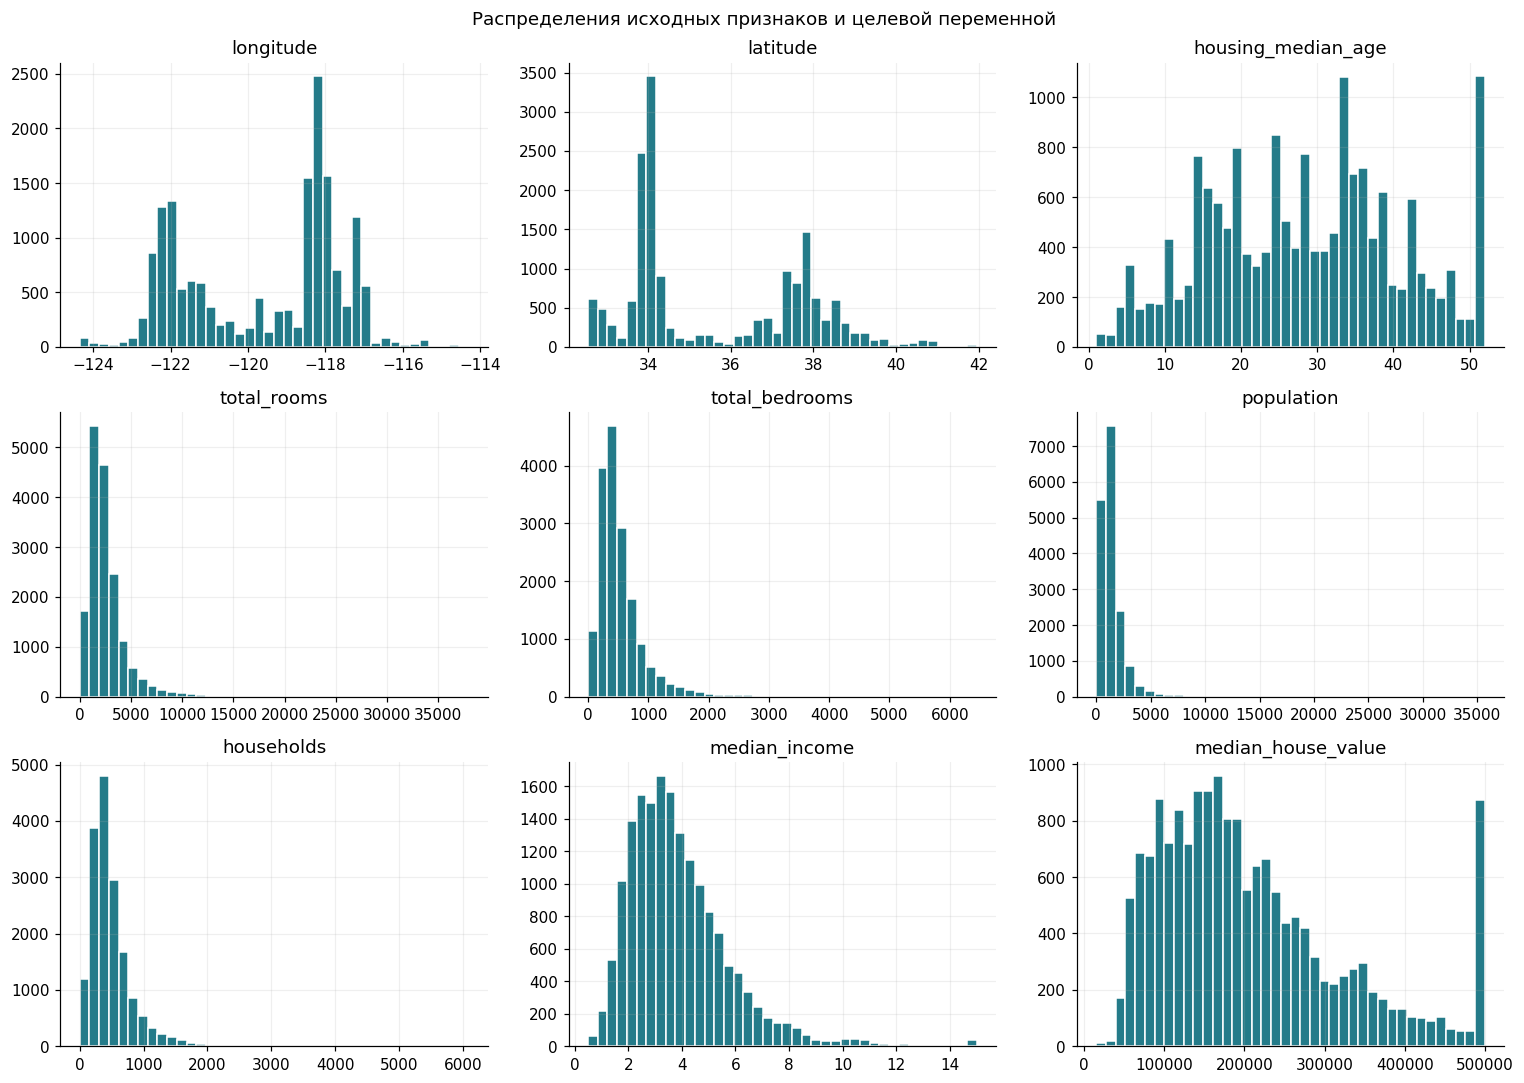

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
})

fig, ax = plt.subplots(figsize=(11, 3))
stats["count"].plot.bar(ax=ax, color="#247b89")
ax.set(title="Число известных значений по столбцам", ylabel="Количество")
plt.tight_layout()
plt.show()

quantiles = ["min", "10%", "25%", "50%", "75%", "90%", "max"]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for column, ax in zip(raw.columns, axes.flat):
    row = stats.loc[column]
    ax.plot(range(7), row[quantiles].to_numpy(dtype=float), "o-", label="Квантили", color="#247b89")
    ax.axhline(row["mean"], color="#d17b32", label="Среднее")
    ax.errorbar(3, row["mean"], yerr=row["std"], fmt="s", color="#ba4545", capsize=5,
                label="Среднее ± std")
    ax.set_xticks(range(7), quantiles, rotation=45)
    ax.set_title(column)
axes.flat[0].legend(fontsize=8)
plt.suptitle("Диапазоны, квантили, средние и стандартные отклонения")
plt.tight_layout()
plt.show()

raw.hist(bins=40, figsize=(14, 10), color="#247b89", edgecolor="white")
plt.suptitle("Распределения исходных признаков и целевой переменной")
plt.tight_layout()
plt.show()

У количества комнат и населения заметны длинные правые хвосты: в некоторых районах значения существенно больше типичных. Поэтому среднее и медиана могут различаться. 

### 3. Проведите предварительную обработку данных, включая обработку отсутствующих значений, кодирование категориальных признаков и нормировка.

Пропусков нет. 
Все входные столбцы содержат числовые измерения, кодирование категорий не требуется.

Меняю только масштаб признаков — выполняю нормировку. Население измеряется тысячами, возраст жилья — десятками, и такие различия мешают устойчивому подбору коэффициентов. Использую стандартизацию по оклонению. Было 1400 с отклонением 200 и средним 1000, стало 2 (на 2 отклоления выше).

Средние и std считаю только по обучающим строкам. Поэтому сначала откладываю 20% районов в test, а остальные использую как train. 

In [4]:
import numpy as np

SEED = 8
assert raw.shape == (17000, 9)
assert raw[TARGET].notna().all()

display(pd.DataFrame({
    "Тип данных": raw.dtypes.astype(str),
    "Пропуски": raw.isna().sum(),
}))
categorical_columns = raw.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()
print("Пропусков:", int(raw.isna().sum().sum()))
print("Текстовых входных столбцов:", len(categorical_columns))

ALL_FEATURES = raw.columns.drop(TARGET).tolist()
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(raw))
cut = int(0.8 * len(raw))
train = raw.iloc[indices[:cut]].copy()
test = raw.iloc[indices[cut:]].copy()
assert set(train.index).isdisjoint(test.index)
assert len(train) + len(test) == len(raw)

,Тип данных,Пропуски
longitude,float64,0
latitude,float64,0
housing_median_age,float64,0
total_rooms,float64,0
total_bedrooms,float64,0
population,float64,0
households,float64,0
median_income,float64,0
median_house_value,float64,0


Пропусков: 0
Текстовых входных столбцов: 0


Проверки подтвердили отсутствие пропусков и текстовых входов.

Выполняем нормировку.

In [5]:
def fit_preprocessor(frame, columns):
    numeric = frame[columns].astype(float).replace([np.inf, -np.inf], np.nan)
    medians = numeric.median()
    if medians.isna().any():
        raise ValueError("Есть полностью пустой обучающий признак")
    filled = numeric.fillna(medians)
    means = filled.mean()
    scales = filled.std(ddof=0).replace(0, 1.0)
    return {"columns": list(columns), "medians": medians,
            "means": means, "scales": scales}

def transform(frame, state):
    numeric = frame[state["columns"]].astype(float).replace([np.inf, -np.inf], np.nan)
    standardized = (numeric.fillna(state["medians"]) - state["means"]) / state["scales"]
    matrix = standardized.to_numpy(dtype=float)
    assert np.isfinite(matrix).all()
    return matrix

In [6]:
state_check = fit_preprocessor(train, ALL_FEATURES)
X_check = transform(train, state_check)
assert np.isfinite(X_check).all()
assert np.allclose(X_check.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_check.std(axis=0), 1, atol=1e-10)

normalization_summary = pd.DataFrame({
    "Среднее до": train[ALL_FEATURES].mean(),
    "Std до": train[ALL_FEATURES].std(ddof=0),
    "Среднее после": X_check.mean(axis=0),
    "Std после": X_check.std(axis=0),
}, index=ALL_FEATURES)
display(normalization_summary.round(6))

normalized_train = pd.DataFrame(X_check, index=train.index, columns=ALL_FEATURES)
example_ids = train.index[:3]
normalization_examples = pd.DataFrame(index=example_ids)
for feature in ["population", "housing_median_age"]:
    normalization_examples[f"{feature}: до"] = train.loc[example_ids, feature]
    normalization_examples[f"{feature}: после"] = normalized_train.loc[example_ids, feature]
display(normalization_examples.round(4))

,Среднее до,Std до,Среднее после,Std после
longitude,-119.558199,2.001333,0.0,1.0
latitude,35.619229,2.134597,0.0,1.0
housing_median_age,28.591324,12.560134,0.0,1.0
total_rooms,2646.570368,2193.860560,-0.0,1.0
total_bedrooms,540.692206,422.960383,0.0,1.0
population,1433.494412,1167.577669,0.0,1.0
households,502.013456,385.525208,-0.0,1.0
median_income,3.872492,1.902280,0.0,1.0


,population: до,population: после,housing_median_age: до,housing_median_age: после
15872,1155.0,-0.2385,52.0,1.8637
1269,1337.0,-0.0826,52.0,1.8637
16267,1783.0,0.2993,46.0,1.3860


В первой таблице видны средние и std до и после нормировки. После преобразования средние train близки к нулю, std — к единице. Во второй показаны те же три района: строки сохранились, но значения населения и возраста жилья пересчитаны. Исходная raw и целевая стоимость не менялись.

Для этой нормировки std считается с делением суммы квадратов отклонений на n, затем берётся квадратный корень (`ddof=0`). В описательной статистике пункта 2 использовано деление на n−1. Параметры train сохраняются и без переоценки применяются к test.

Посмотрим на первую строку с населением 1155. В верхней таблице для населения указаны среднее 1433.494412 и std 1167.577669:
`(1155 − 1433.494412) / 1167.577669 ≈ −0.2385`

### 4. Разделите данные на обучающий и тестовый наборы данных.

Использую 80% строк для обучения и 20% для проверки. Получилось 13600 районов train и 3400 районов test. На train подбираются параметры обработки и коэффициенты модели, по test проверяется результат на строках, которые обучение не видело.

In [7]:
split_summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "fraction": [len(train) / len(raw), len(test) / len(raw)],
}, index=["train", "test"])
display(split_summary)
assert set(train.index).isdisjoint(test.index)
assert len(train) + len(test) == len(raw)

,rows,fraction
train,13600,0.8
test,3400,0.2


Проверка подтвердила, что train и test не пересекаются и вместе содержат все 17000 строк. 

### 5. Реализуйте линейную регрессию с использованием метода наименьших квадратов без использования сторонних библиотек, кроме NumPy и Pandas (для использования коэффициентов использовать библиотеки тоже нельзя). Использовать минимизацию суммы квадратов разностей между фактическими и предсказанными значениями для нахождения оптимальных коэффициентов.

Подбираю коэффициенты линейной формулы так, чтобы сумма квадратов ошибок была минимальной. Для поиска использую собственный градиентный спуск. В коде сумма делится на число строк (MSE); лучшие коэффициенты от этого не меняются.

`прогноз = a * z + b`

`новый коэффициент = старый − learning_rate × градиент`

В нашем примере при a = 0 градиент равен −16. Возьмём learning_rate = 0.1:

`новый a = 0 − 0.1 × (−16) = 1.6`

Теперь прогноз — 3.2, ошибка — 0.64 вместо 16. Уже ближе.

| Шаг | Коэффициент a | Прогноз при x = 2 |
|---|---|---|
| Начало | 0 | 0 |
| 1 | 1.6 | 3.2 |
| 2 | 1.92 | 3.84 |
| 3 | 1.984 | 3.968 |


Это и есть спуск: каждый раз пересчитываем градиент и двигаем коэффициент в сторону уменьшения ошибки.

В полной модели 8 признаков, поэтому подбираем 9 чисел: восемь коэффициентов и свободный член b.
Обучение идёт так:
1. Получаем прогнозы для 13600 районов train.
2. Считаем общую среднюю ошибку.
3. Получаем градиент — по одному числу для каждого из девяти коэффициентов.
4. Обновляем все коэффициенты и повторяем.
То есть ошибка у модели одна общая, а подсказок «куда менять вес» — девять. Для всех весов действует уже знакомое правило:

`новый вес = старый вес − learning_rate × его градиент`

In [8]:
def fit_ols_gd(X, y, max_iter=100_000, tolerance=1e-8):
    y = np.asarray(y, dtype=float)
    D = np.column_stack([np.ones(len(X)), X])
    y_mean = float(y.mean())
    y_scale = float(y.std())
    if y_scale == 0:
        y_scale = 1.0
    t = (y - y_mean) / y_scale
    if not np.isfinite(t).all():
        raise ValueError("Ответы должны быть конечными числами")

    G = D.T @ D / len(D)
    g = D.T @ t / len(D)
    constant = float(t @ t / len(t))
    bound = float(np.abs(G).sum(axis=1).max())
    learning_rate = 0.5 / max(bound, 1e-12)
    weights = np.zeros(D.shape[1])
    history = []
    updates = 0

    for iteration in range(max_iter):
        gradient = 2 * (G @ weights - g)
        if iteration % 100 == 0:
            loss = constant - 2 * g @ weights + weights @ G @ weights
            history.append((iteration, float(loss)))
        if np.max(np.abs(gradient)) < tolerance:
            break
        weights -= learning_rate * gradient
        updates += 1

    gradient = 2 * (D.T @ (D @ weights - t)) / len(D)
    final_loss = float(np.mean((D @ weights - t) ** 2))
    gradient_max = float(np.max(np.abs(gradient)))
    converged = gradient_max < tolerance
    history.append((updates, final_loss))
    return {"weights": weights, "y_mean": y_mean, "y_scale": y_scale,
            "history": np.asarray(history), "converged": converged,
            "gradient_max": gradient_max,
            "iterations": updates, "learning_rate": learning_rate}

По найденным коэффициентам считаю прогнозы стоимости в долларах.

In [9]:
def predict_ols(X, model):
    D = np.column_stack([np.ones(len(X)), X])
    return (D @ model["weights"]) * model["y_scale"] + model["y_mean"]

Проверяю обучение на прямой y = 3 + 2 × x: алгоритм должен восстановить коэффициенты 3 и 2.

In [10]:
toy_X = np.array([[-2.0], [-1.0], [0.0], [1.0], [2.0]])
toy_y = 3.0 + 2.0 * toy_X[:, 0]
toy_model = fit_ols_gd(toy_X, toy_y)
assert toy_model["converged"]
assert np.allclose(predict_ols(toy_X, toy_model), toy_y, atol=1e-5)
toy_bias = toy_model["y_mean"] + toy_model["y_scale"] * toy_model["weights"][0]
toy_slope = toy_model["y_scale"] * toy_model["weights"][1]
assert np.isclose(toy_bias, 3.0, atol=1e-5)
assert np.isclose(toy_slope, 2.0, atol=1e-5)
display(pd.DataFrame({"ожидается": [3.0, 2.0], "получено": [toy_bias, toy_slope]},
                     index=["Свободный член", "Коэффициент при x"]))

,ожидается,получено
Свободный член,3.0,3.0
Коэффициент при x,2.0,2.0


Коэффициенты восстановлены верно. Готовый библиотечный подбор коэффициентов не использовался.

### 6. Постройте **три модели** с различными наборами признаков.

Три раза обучаю один алгоритм на тех же районах, но с разными входными столбцами. `income` использует только доход. `income_location` — доход и координаты. `all` — все восемь исходных признаков. Это позволяет отдельно проверить вклад расположения и остальных характеристик.

Для каждого набора считаю параметры нормировки по его столбцам train, подбираю коэффициенты и сохраняю прогнозы в `fitted`. Целевую стоимость среди входов не оставляю. В таблице `updates` показывает число обновлений весов, а `max_abs_gradient` — достигнутую точность остановки. Качество прогнозов посчитаю в пункте 7.

In [11]:
y_train = train[TARGET].to_numpy(dtype=float)
y_test = test[TARGET].to_numpy(dtype=float)
FEATURE_SETS = {
    "income": ["median_income"],
    "income_location": ["median_income", "latitude", "longitude"],
    "all": ALL_FEATURES,
}

fitted, training_rows = {}, []
for name, columns in FEATURE_SETS.items():
    state = fit_preprocessor(train, columns)
    X_train = transform(train, state)
    X_test = transform(test, state)
    model = fit_ols_gd(X_train, y_train)
    if not model["converged"]:
        raise RuntimeError(f"Модель {name} не достигла заданной точности")
    fitted[name] = {
        "preprocessor": state, "model": model,
        "train_pred": predict_ols(X_train, model),
        "test_pred": predict_ols(X_test, model),
    }
    training_rows.append({
        "model": name, "features": len(columns),
        "updates": model["iterations"],
        "max_abs_gradient": model["gradient_max"],
        "columns": ", ".join(columns),
    })
training_table = pd.DataFrame(training_rows).set_index("model")
display(training_table)

,features,updates,max_abs_gradient,columns
model,,,,
income,1,1,1.926825e-15,median_income
income_location,3,462,9.897064e-09,"median_income, latitude, longitude"
all,8,3904,9.983680e-09,"longitude, latitude, housing_median_age, total..."


Все три модели достигли заданного порога градиента. В опыте с одним признаком понадобилось одно обновление, в полном — 3904. Это число шагов подбора весов, а не количество правильных прогнозов.

Ниже пересчитываю коэффициенты полной модели в исходные единицы CSV. Проверяю, что прогноз по исходным признакам и пересчитанным весам совпадает с прогнозом по нормированным входам.

In [12]:
full = fitted["all"]
state, model = full["preprocessor"], full["model"]
raw_coefficients = model["y_scale"] * model["weights"][1:] / state["scales"].to_numpy()
raw_intercept = model["y_mean"] + model["y_scale"] * model["weights"][0]
raw_intercept -= raw_coefficients @ state["means"].to_numpy()
coefficient_table = pd.DataFrame({
    "coefficient": [raw_intercept] + raw_coefficients.tolist()
}, index=["intercept"] + state["columns"])
display(coefficient_table.round(6))
assert np.allclose(
    test[state["columns"]].to_numpy() @ raw_coefficients + raw_intercept,
    full["test_pred"], atol=1e-5,
)

,coefficient
intercept,-3.613583e+06
longitude,-4.298902e+04
latitude,-4.264046e+04
housing_median_age,1.141461e+03
total_rooms,-8.824780e+00
total_bedrooms,1.188410e+02
population,-3.626079e+01
households,4.119908e+01
median_income,4.062899e+04


Прогнозы совпали. `intercept` — свободный член, остальные строки — коэффициенты при признаках. Их величины нельзя напрямую сравнивать как важность: у столбцов разные единицы, а сами признаки связаны друг с другом. Коэффициенты описывают найденную формулу и не доказывают причинного влияния на цену.

### 7. Для каждой модели проведите оценку производительности, используя метрику коэффициент детерминации, чтобы измерить, насколько хорошо модель соответствует данным.

R² сравнивает ошибку модели с ошибкой простого прогноза, который всем районам выдаёт среднюю цену: `R² = 1 − ошибка модели / ошибка среднего`. В обоих случаях ошибка — сумма квадратов разностей с настоящими ценами.

При точных прогнозах R² = 1, при такой же ошибке, как у среднего, R² = 0. Если модель ошибается сильнее, R² отрицательный. Значение 0.65 не означает 65% правильно угаданных цен.

Функция `r2_score_manual` получает настоящие ответы и прогнозы, возвращает одно число. Проверяю её на точном совпадении и постоянном среднем, затем оцениваю три модели. В таблице train_R2 относится к обучающим строкам, test_R2 — к отложенным. Дополнительный ориентир `baseline` выдаёт среднюю цену train для всех районов test.

In [13]:
def r2_score_manual(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if y_true.shape != y_pred.shape:
        raise ValueError("Форма ответов и прогнозов должна совпадать")
    sse = float(np.sum((y_true - y_pred) ** 2))
    sst = float(np.sum((y_true - y_true.mean()) ** 2))
    return np.nan if sst == 0 else 1 - sse / sst


assert np.isclose(r2_score_manual(toy_y, toy_y), 1.0)
assert np.isclose(r2_score_manual(toy_y, np.full(len(toy_y), toy_y.mean())), 0.0)
baseline = np.full(len(y_test), y_train.mean())
print("R² базового прогноза:", r2_score_manual(y_test, baseline))

results = []
for name, item in fitted.items():
    results.append({
        "model": name, "features": len(FEATURE_SETS[name]),
        "train_R2": r2_score_manual(y_train, item["train_pred"]),
        "test_R2": r2_score_manual(y_test, item["test_pred"]),
        "updates": item["model"]["iterations"],
        "max_abs_gradient": item["model"]["gradient_max"],
    })
comparison = pd.DataFrame(results).set_index("model")
display(comparison)

R² базового прогноза: -0.0003507942579983325


,features,train_R2,test_R2,updates,max_abs_gradient
model,,,,,
income,1,0.478912,0.477657,1,1.926825e-15
income_location,3,0.587044,0.593947,462,9.897064e-09
all,8,0.638880,0.650353,3904,9.983680e-09


Ориентир по среднему train получил test R² около −0.000351: средние цены двух частей немного различаются. Три модели дали 0.477657, 0.593947 и 0.650353. Все они лучше этого постоянного прогноза.

### 8. Сравните результаты трех моделей и сделайте выводы о том, какие признаки работают лучше всего для каждой модели.

Модель только по доходу получила test R² = 0.477657. Добавление координат увеличило результат до 0.593947, то есть на 0.116290. Все восемь признаков дали 0.650353 — ещё на 0.056406 больше. На одинаковых проверочных районах полезными оказались и расположение, и остальные характеристики.

Слева сравниваю train_R2 и test_R2. У полной модели это 0.638880 и 0.650353: сильного падения на отложенных строках нет. Справа показываю, как при подборе весов уменьшалась обучающая ошибка. Эта линия проверяет работу оптимизации, но не заменяет оценку на test.

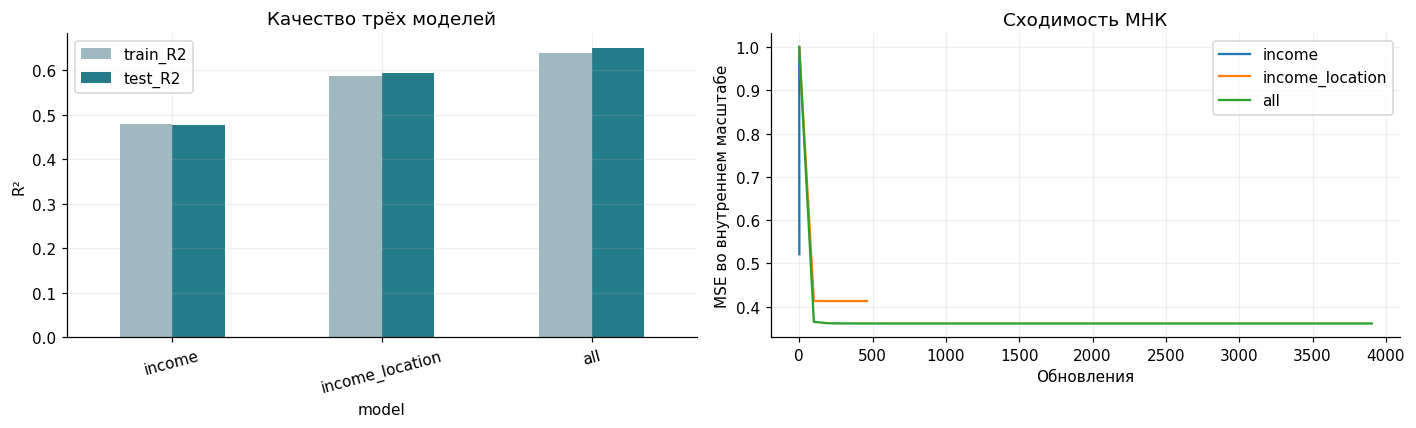

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
comparison[["train_R2", "test_R2"]].plot.bar(ax=axes[0], color=["#9ebac0", "#247b89"])
axes[0].set(title="Качество трёх моделей", ylabel="R²")
axes[0].tick_params(axis="x", rotation=15)
for name, item in fitted.items():
    history = item["model"]["history"]
    axes[1].plot(history[:, 0], history[:, 1], label=name)
axes[1].set(title="Сходимость МНК", xlabel="Обновления", ylabel="MSE во внутреннем масштабе")
axes[1].legend()
plt.tight_layout()
plt.show()

В следующей таблице `actual_value` — настоящая цена, `predicted_value` — прогноз, `residual` — разница «факт − прогноз». Положительный остаток означает недооценку, отрицательный — завышение.

На левом рисунке одна точка соответствует району; попадание на диагональ означает точный прогноз. На правом показаны остатки, где горизонтальная линия 0 соответствует отсутствию ошибки.

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,actual_value,predicted_value,residual
3259,-117.86,33.75,5.0,187.0,49.0,207.0,51.0,1.80,154200.0,91594.85,62605.15
8390,-118.47,34.26,35.0,1898.0,344.0,1123.0,347.0,5.58,218400.0,282799.36,-64399.36
5873,-118.20,33.93,36.0,1191.0,345.0,1193.0,295.0,2.52,138800.0,163729.35,-24929.35
5931,-118.21,34.09,34.0,1660.0,412.0,1678.0,382.0,2.77,148200.0,155125.90,-6925.90
9640,-119.46,36.25,32.0,1702.0,348.0,1016.0,350.0,2.50,73600.0,118183.34,-44583.34
4156,-117.99,34.04,30.0,4468.0,959.0,4027.0,938.0,3.18,168300.0,138019.13,30280.87
11398,-121.22,37.81,20.0,1811.0,352.0,1191.0,327.0,4.01,121500.0,167298.95,-45798.95
6791,-118.30,34.11,52.0,3136.0,675.0,1213.0,606.0,3.58,391900.0,255909.42,135990.58


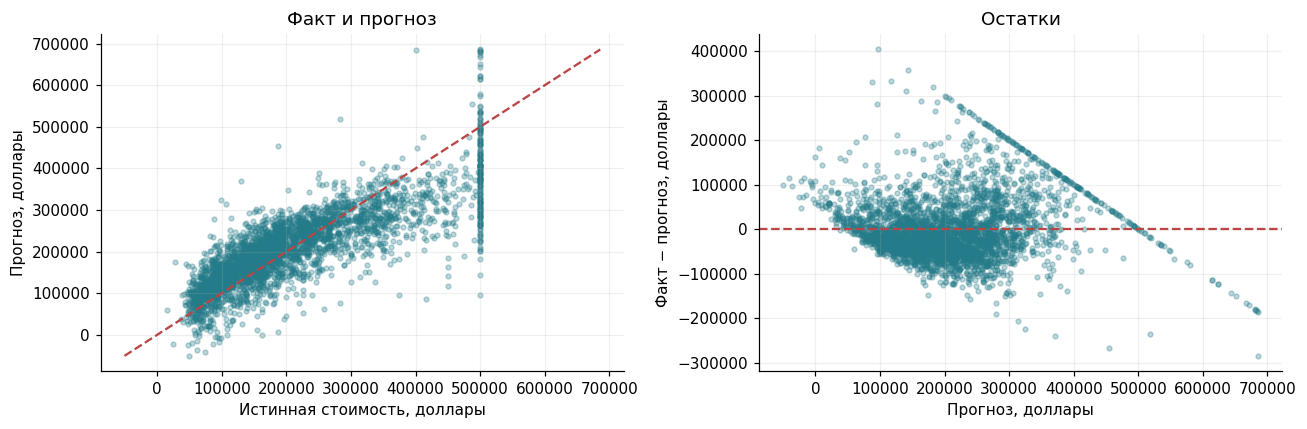

In [15]:
pred = full["test_pred"]
examples = test[ALL_FEATURES].head(8).copy()
examples["actual_value"] = y_test[:8]
examples["predicted_value"] = pred[:8]
examples["residual"] = y_test[:8] - pred[:8]
display(examples.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, pred, s=10, alpha=0.3, color="#247b89")
limits = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(limits, limits, "--", color="#ba4545")
axes[0].set(title="Факт и прогноз", xlabel="Истинная стоимость, доллары", ylabel="Прогноз, доллары")
axes[1].scatter(pred, y_test - pred, s=10, alpha=0.3, color="#247b89")
axes[1].axhline(0, linestyle="--", color="#ba4545")
axes[1].set(title="Остатки", xlabel="Прогноз, доллары", ylabel="Факт − прогноз, доллары")
plt.tight_layout()
plt.show()

У полной модели получилось 17 отрицательных прогнозов. Такие цены не имеют практического смысла, но линейная формула не запрещает их. Оставляю эти ответы в оценке, чтобы не скрывать ограничение метода.

Лучшее test R² среди трёх проверенных наборов получили все восемь признаков. Это не означает точных прогнозов для каждого района или гарантии на других данных. Предсказывается медианная цена района, а не стоимость отдельной квартиры.

In [16]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if y_true.shape != y_pred.shape:
        raise ValueError("Форма ответов и прогнозов должна совпадать")

    errors = y_true - y_pred
    squared_errors = errors ** 2
    mse = float(squared_errors.mean())

    return {
        "R²": r2_score_manual(y_true, y_pred),
        "MAE": float(np.abs(errors).mean()),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
    }


assert regression_metrics(toy_y, toy_y) == {"R²": 1.0, "MAE": 0.0, "MSE": 0.0, "RMSE": 0.0}

train_metrics = pd.DataFrame.from_dict({
    name: regression_metrics(y_train, item["train_pred"])
    for name, item in fitted.items()
}, orient="index")
test_metrics = pd.DataFrame.from_dict({
    name: regression_metrics(y_test, item["test_pred"])
    for name, item in fitted.items()
}, orient="index")

baseline_price = y_train.mean()
train_metrics.loc["baseline"] = regression_metrics(y_train, np.full_like(y_train, baseline_price))
test_metrics.loc["baseline"] = regression_metrics(y_test, np.full_like(y_test, baseline_price))
metric_format = {"R²": "{:.6f}", "MAE": "{:,.2f}", "MSE": "{:,.2f}", "RMSE": "{:,.2f}"}

display(train_metrics.style.format(metric_format, thousands=" ").set_caption("Обучающая выборка"))
display(test_metrics.style.format(metric_format, thousands=" ").set_caption("Тестовая выборка"))

,R²,MAE,MSE,RMSE
income,0.478912,62 332.90,6 968 297 994.77,83 476.33
income_location,0.587044,54 527.16,5 522 286 851.33,74 312.09
all,0.638880,50 650.90,4 829 110 183.02,69 491.80
baseline,0.000000,91 286.04,13 372 586 908.05,115 639.90


,R²,MAE,MSE,RMSE
income,0.477657,63 985.31,7 189 013 383.75,84 788.05
income_location,0.593947,55 895.05,5 588 510 019.30,74 756.34
all,0.650353,51 287.26,4 812 191 327.89,69 369.96
baseline,-0.000351,92 670.44,13 767 829 432.03,117 336.39


### 9. Бонусное задание

- Ввести синтетический признак при построении модели

Создаю новый столбец `rooms_per_household = total_rooms / households` — число комнат на домохозяйство. В крупном районе комнат больше просто из-за его размера; отношение позволяет описать жильё отдельно от общего размера района.

Сравниваю модель на всех восьми признаках с такой же моделью, у которой добавлен этот девятый столбец. Строки train/test и способ обучения сохраняю. Цену в формулу нового признака не включаю.

Функция возвращает копию таблицы с добавленным отношением. Если знаменатель равен нулю, записывается пропуск, который затем обрабатывается медианой train. Специально создавать пропуски в нашем файле не требуется.

,features,train_R2,test_R2
all,8,0.638880,0.650353
all_plus_ratio,9,0.640098,0.650985


Изменение test R²: 0.0006317969598560458


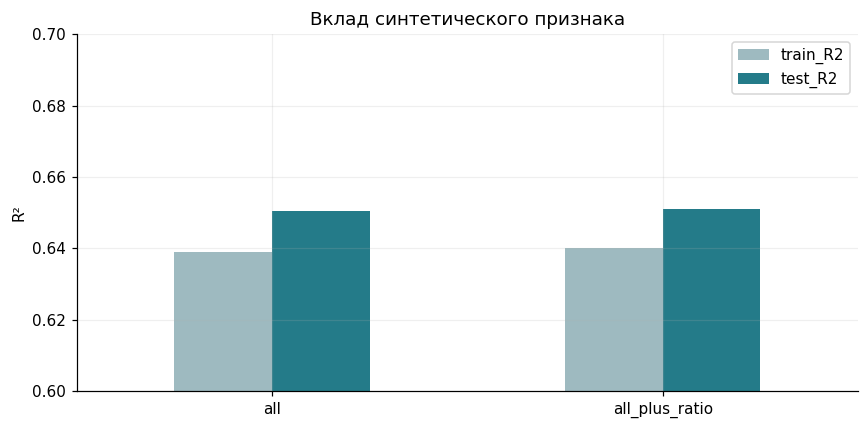

In [17]:
def add_synthetic_feature(frame):
    result = frame.copy()
    denominator = result["households"].replace(0, np.nan)
    result["rooms_per_household"] = result["total_rooms"] / denominator
    return result

bonus_train = add_synthetic_feature(train)
bonus_test = add_synthetic_feature(test)
bonus_columns = ALL_FEATURES + ["rooms_per_household"]
bonus_state = fit_preprocessor(bonus_train, bonus_columns)
bonus_model = fit_ols_gd(transform(bonus_train, bonus_state), y_train)
assert bonus_model["converged"]
bonus_prediction = predict_ols(transform(bonus_test, bonus_state), bonus_model)
bonus_train_prediction = predict_ols(transform(bonus_train, bonus_state), bonus_model)
bonus_r2 = r2_score_manual(y_test, bonus_prediction)
bonus_comparison = pd.DataFrame({
    "features": [8, 9],
    "train_R2": [comparison.loc["all", "train_R2"], r2_score_manual(y_train, bonus_train_prediction)],
    "test_R2": [comparison.loc["all", "test_R2"], bonus_r2],
}, index=["all", "all_plus_ratio"])
display(bonus_comparison)
print("Изменение test R²:", float(bonus_r2 - comparison.loc["all", "test_R2"]))
bonus_comparison[["train_R2", "test_R2"]].plot.bar(
    figsize=(8, 4), color=["#9ebac0", "#247b89"], ylim=(0.6, 0.7), rot=0,
    title="Вклад синтетического признака", ylabel="R²",
)
plt.tight_layout()
plt.show()

С новым отношением test R² вырос с 0.650353 до 0.650985, то есть на 0.000632. Вклад положительный, но небольшой по сравнению с добавлением координат. На другом разбиении такое улучшение не гарантировано.

В таблице число признаков изменилось с 8 до 9. Вертикальная шкала графика начинается с 0.6, чтобы разница была видна; размер прироста следует оценивать по числам в таблице. Исходный файл данных не изменялся.

In [18]:
bonus_index = ["all", "all_plus_ratio"]
bonus_train_metrics = pd.DataFrame([
    train_metrics.loc["all"].to_dict(),
    regression_metrics(y_train, bonus_train_prediction),
], index=bonus_index)
bonus_test_metrics = pd.DataFrame([
    test_metrics.loc["all"].to_dict(),
    regression_metrics(y_test, bonus_prediction),
], index=bonus_index)

display(bonus_train_metrics.style.format(metric_format, thousands=" ").set_caption("Бонус: обучающая выборка"))
display(bonus_test_metrics.style.format(metric_format, thousands=" ").set_caption("Бонус: тестовая выборка"))

,R²,MAE,MSE,RMSE
all,0.638880,50 650.90,4 829 110 183.02,69 491.80
all_plus_ratio,0.640098,50 640.84,4 812 818 379.94,69 374.48


,R²,MAE,MSE,RMSE
all,0.650353,51 287.26,4 812 191 327.89,69 369.96
all_plus_ratio,0.650985,51 296.70,4 803 495 905.41,69 307.26
